# Independent square-wave pulse duration and calibration

Uses the **installed PWB v1 `TDC:WIDTH:*` commands**. No API, SCPI server, or HDL rebuild is needed.

Connect the manual generator output to **DIO2_P / E1 pin 7**, and its ground to **E1 pin 25 or 26**.
Set actual levels at the FPGA to **0–3.3 V** (3.3 Vpp, +1.65 V offset for a symmetric square waveform).
Use the generator's **High-Z load setting** when appropriate and verify the levels with the scope.
Leave **DIO1_P / E1 pin 5 disconnected from the generator output and its signal cable**. The FPGA drives
this pin solely to make internal capture windows; the window is not a stimulus for this test.
Do not connect two outputs together. The manual generator must already be running before capture.

The installed firmware needs internal pulse markers. This notebook uses asynchronous windows slightly
shorter than the entered generator period, or one 4 ns step longer near the 1 MHz window limit. It accepts a frame only when the FPGA reports one complete
rise/fall pair. Boundary-cut, empty and malformed frames remain in the CSV but do not enter width statistics.
**This samples complete pulses; it does not capture every incoming pulse consecutively or measure frequency.**
The FPGA window output stops after each burst. The manual generator remains under your control.

The notebook provides:
1. HIGH duration versus `duty / frequency`, plus an independent scope reference if entered.
2. Candidate **separate 250 MHz RISE/FALL code-density LUTs**, uploaded through the existing commands.
3. A local, one-point duration correction and a fresh validation capture.

Fine LUT calibration needs phases spread uniformly over the FPGA's 4 ns sample interval.
An independent generator alone does not guarantee this. Use a slightly detuned frequency (for example
100003 Hz), inspect the histograms, and repeat at different frequencies/duties. Histogram gates detect
obvious failures; passing them does not prove uniform phase or absolute accuracy. Window selection can
bias the retained sample distribution. Reference correction is valid only at the tested operating point.
Vpp and offset are **entered metadata**, not voltage measurements from the digital input.

## 1. Enter the generator settings

Duty is a percentage. Enter the generator's actual settings below; this notebook does not program it.
`SCOPE_HIGH_NS` optionally replaces the nominal HIGH duration with an independently measured reference.
Choose an `envscpi` kernel with NumPy and Matplotlib. All transport code is included in this notebook.

In [38]:
RP_IP = "169.254.77.151"
SCPI_PORT = 5000
FREQUENCY_HZ = 100_003.0
DUTY_PERCENT = 50.0
VPP_V = 3.3
OFFSET_V = 1.65
SCOPE_HIGH_NS = None       # Optional independent measured HIGH duration, in ns.

FRAME_COUNT = 8192         # Acquisition windows per burst, not accepted-pulse count.
CAL_BATCHES = 12           # Increase if too few complete pulses / phase samples.
HOST_TIMEOUT_S = 30.0
MIN_EDGE_SAMPLES = 20_000
MIN_POPULATED_BINS = 32
KNOWN_DEAD_ZONES = []      # Inclusive raw-index pairs, only after physical characterization.
RESULTS_PARENT = "tdc_external_square_results"

In [39]:
import csv
import json
import math
import socket
import time
import warnings
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

FIELDS = ("frame_id", "flags", "coarse_ticks", "rise_raw", "fall_raw", "width_ps")
FLAG_NAMES = {0:"VALID", 1:"NO_RISE", 2:"NO_FALL", 3:"HIGH_START", 4:"EXTRA_EDGES",
              5:"TRIGGER_TIMEOUT", 7:"FINE_INVALID", 8:"COARSE_ONLY", 9:"CALIBRATED",
              10:"BOUNDARY", 11:"SATURATED", 12:"OUT_OF_RANGE"}

def make_plan(frequency, duty, vpp, offset, frame_count, host_timeout, scope_high=None):
    if not all(math.isfinite(float(x)) for x in (frequency, duty, vpp, offset, host_timeout)):
        raise ValueError("Generator settings and timeout must be finite")
    if not 0 < frequency <= 1_000_000 or not 0 < duty < 100:
        raise ValueError("Use 0 < frequency <= 1 MHz and 0 < duty < 100 percent")
    if vpp <= 0 or offset-vpp/2 < -1e-9 or offset+vpp/2 > 3.3+1e-9:
        raise ValueError("Entered levels must remain in 0–3.3 V; check Vpp, offset and generator load setting")
    if isinstance(frame_count, bool) or not isinstance(frame_count, int) or not 1 <= frame_count <= 16384:
        raise ValueError("FRAME_COUNT must be an integer from 1 to 16384; hardware capacity is also queried")
    period = 1e9 / frequency
    high, low = period*duty/100, period*(1-duty/100)
    if min(high, low) < 8 or high > 4_294_000:
        raise ValueError("Use HIGH/LOW >= 8 ns and HIGH <= 4.294 ms for this width capture")
    # Normally reduce W by 1/8 of LOW to walk relative phase.
    # At the 1 MHz window limit, use a 4 ns longer window if matching
    # periods would barely move the boundary over one burst. Any extra
    # edge at a boundary remains rejected by the existing FPGA flags.
    window = max(1000, int(math.floor((period-low/8)/4))*4)
    if abs(window-period) < 1.0:
        window += 4
    if window > period+4+1e-6 or window <= high+8 or window > 8_589_934_588:
        raise ValueError("No suitable <=1 MHz capture window; reduce frequency/duty to leave a LOW gap")
    if host_timeout <= frame_count*window*1e-9 + 1:
        raise ValueError("Increase HOST_TIMEOUT_S beyond burst duration plus 1 s")
    reference = high if scope_high is None else float(scope_high)
    if not math.isfinite(reference) or reference <= 0 or reference >= period:
        raise ValueError("SCOPE_HIGH_NS must be a finite HIGH duration shorter than the entered period")
    return dict(frequency_hz=float(frequency), duty_percent=float(duty), vpp_v=float(vpp),
                offset_v=float(offset), low_v=float(offset-vpp/2), high_v=float(offset+vpp/2),
                source_period_ns=period, nominal_high_ns=high, nominal_low_ns=low,
                reference_high_ns=reference, reference_source="generator settings" if scope_high is None else "scope",
                window_ns=window, window_high_ns=window//2, frames=frame_count,
                host_timeout_s=float(host_timeout), expected_complete_fraction=max(0,(min(low,window-high)-max(0,window-period))/period))

def json_value(value):
    if isinstance(value, np.ndarray): return value.tolist()
    if isinstance(value, np.generic): return value.item()
    if isinstance(value, Path): return str(value)
    raise TypeError(type(value).__name__)

def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, default=json_value, allow_nan=False), encoding="utf-8")

def complete_rows(capture):
    rows = np.asarray(capture["records"], dtype=np.uint64).reshape(-1,6)
    return rows[(rows[:,1] & 1) != 0]

def summarize(capture, correction_ns=0.0):
    rows = complete_rows(capture)
    if not len(rows):
        raise RuntimeError(
            f"No complete pulse in {len(capture['records'])} frames. "
            f"Flags: {capture.get('flag_counts', {})}. "
            "HIGH_START with NO_FALL can mean the window repeatedly cuts a pulse. "
            "Re-run the settings/plan cells to apply the window phase walk; "
            "also check the input on E1 pin 7 and the saved CSV."
        )
    widths = rows[:,5].astype(float)/1000 + correction_ns
    reference = capture["plan"]["reference_high_ns"]
    return dict(accepted_pulses=len(rows), total_frames=len(capture["records"]),
                rejected_frames=len(capture["records"])-len(rows),
                mean_high_ns=float(np.mean(widths)), std_high_ns=float(np.std(widths,ddof=1)) if len(widths)>1 else 0.0,
                mean_error_ns=float(np.mean(widths)-reference), reference_high_ns=reference,
                min_high_ns=float(np.min(widths)), max_high_ns=float(np.max(widths)),
                fine_pulses=int(np.count_nonzero(rows[:,1]&512)), correction_ns=float(correction_ns))

def guard_reference_capture(capture, summary):
    """Block fitting/correction of a missing-signal or glitch-only capture.

    This checks aggregate quality; it does not filter individual widths against
    the expected value or change the raw measurement statistics.
    """
    problems=[]
    if not capture.get("acquisition_ok") or capture.get("cleanup_errors"):
        problems.append("acquisition/cleanup was not confirmed")
    if summary["accepted_pulses"] < 100:
        problems.append(f"only {summary['accepted_pulses']} complete pulses; need at least 100")
    actual=summary["accepted_pulses"]/max(1,summary["total_frames"])
    expected=capture["plan"]["expected_complete_fraction"]
    if actual < expected/4:
        problems.append(f"complete-frame fraction {actual:.3%} is far below the predicted {expected:.1%}")
    reference=capture["plan"]["reference_high_ns"]
    tolerance=max(2*capture["tick_ps"]/1000,0.1*reference)
    if abs(summary["mean_error_ns"]) > tolerance:
        problems.append(f"raw mean {summary['mean_high_ns']:.3f} ns differs too much from reference {reference:.3f} ns")
    if problems:
        raise RuntimeError("Reference calibration blocked: "+"; ".join(problems)+
                           ". Verify the actual waveform at E1 pin 7 before calibrating. Raw CSV is retained.")

def show_capture(capture, correction_ns=0.0):
    result = summarize(capture,correction_ns)
    print(json.dumps(result,indent=2))
    rows=complete_rows(capture);widths=rows[:,5].astype(float)/1000+correction_ns
    fig,axes=plt.subplots(1,2,figsize=(12,3.6))
    axes[0].plot(rows[:,0],widths,".",ms=2)
    axes[0].axhline(capture["plan"]["reference_high_ns"],color="C3",label="Reference HIGH")
    axes[0].set(xlabel="Acquisition frame (gaps are rejected frames)",ylabel="HIGH duration (ns)")
    axes[0].legend();axes[1].hist(widths,bins=min(60,max(5,len(np.unique(widths)))))
    axes[1].set(xlabel="HIGH duration (ns)",ylabel="Complete pulses")
    fig.tight_layout();plt.show()
    return result

In [40]:
plan = make_plan(FREQUENCY_HZ,DUTY_PERCENT,VPP_V,OFFSET_V,FRAME_COUNT,HOST_TIMEOUT_S,SCOPE_HIGH_NS)
RUN_DIR = Path(RESULTS_PARENT)/datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
print(f"Generator levels: {plan['low_v']:.3f} to {plan['high_v']:.3f} V")
print(f"Expected HIGH: {plan['nominal_high_ns']:.3f} ns; LOW: {plan['nominal_low_ns']:.3f} ns")
print(f"Internal window: {plan['window_ns']} ns at 50% drive duty; E1 pin 5 must be isolated")
print(f"Approximate complete-frame fraction with drifting phase: {plan['expected_complete_fraction']:.1%}")
print(f"Results directory: {RUN_DIR}")
if abs(plan['window_ns']-plan['source_period_ns']) < 4:
    print("Window and source periods nearly match. Detune the manual source slightly if capture or phase coverage is poor.")
if plan["window_ns"] > plan["source_period_ns"]:
    print("A 4 ns longer window walks the boundary at the 1 MHz limit; boundary-extra-edge frames are rejected.")


Generator levels: 0.000 to 3.300 V
Expected HIGH: 4999.850 ns; LOW: 4999.850 ns
Internal window: 9372 ns at 50% drive duty; E1 pin 5 must be isolated
Approximate complete-frame fraction with drifting phase: 43.7%
Results directory: tdc_external_square_results\20261016T122853_482851Z


## 2. Transport and capture

The following cell only defines functions. Each capture then uses the existing `PULSE:TIMING`,
`PULSE:OUTPUT`, `TDC:INPUT SINGLE`, and `TDC:WIDTH:*` commands. It starts the internal window before ARM,
preserves every returned record, and stops the FPGA output and aborts acquisition on every exit.
Running these cells does not stop or program the manual generator.

In [41]:
class SCPI:
    def __init__(self,host,port):
        self.sock=socket.create_connection((host,port),timeout=5)
        self.reader=self.sock.makefile("rb")
    def send(self,command):
        self.sock.sendall((command+"\r\n").encode("ascii"))
    def query(self,command):
        self.send(command);line=self.reader.readline(65536)
        if not line or not line.endswith(b"\n"):
            raise RuntimeError("Incomplete SCPI reply: "+command)
        return line.decode("ascii").strip()
    def check(self,command):
        error=self.query("SYST:ERR:NEXT?")
        if int(error.split(",",1)[0])!=0:
            raise RuntimeError(f"{command}: {error}")
    def write(self,command):
        self.send(command);self.check(command)
    def ask(self,command):
        value=self.query(command);self.check(command);return value
    def close(self):
        try:self.reader.close()
        finally:self.sock.close()

def wait_idle(client,timeout):
    deadline=time.monotonic()+timeout
    while True:
        status=int(client.ask("TDC:WIDTH:STATUS?"))
        if not status&1:return status
        if time.monotonic()>=deadline:raise TimeoutError("TDC width acquisition remained BUSY")
        time.sleep(0.01)

def stop_fpga(client_factory=SCPI):
    client=client_factory(RP_IP,SCPI_PORT)
    try:
        client.write("PULSE:OUTPUT OFF")
        client.write("TDC:WIDTH:ABORT");wait_idle(client,5)
        if client.ask("PULSE:OUTPUT?") not in ("0","OFF"):raise RuntimeError("OFF was not confirmed")
    finally:client.close()
    print("FPGA capture stopped; E1 pin 5 LOW. Manual generator is still under your control.")

def save_capture(capture):
    stem=RUN_DIR/capture["label"]
    stem.parent.mkdir(parents=True,exist_ok=True)
    with stem.with_suffix(".csv").open("w",newline="",encoding="utf-8") as output:
        writer=csv.writer(output);writer.writerow((*FIELDS,"complete","decoded_flags"))
        for row in capture["records"]:
            writer.writerow((*row,int(bool(row[1]&1)),"|".join(name for bit,name in FLAG_NAMES.items() if row[1]&(1<<bit))))
    save_json(stem.with_suffix(".json"),{key:value for key,value in capture.items() if key!="records"})

def capture_burst(label,fine=False,client_factory=SCPI):
    client=client_factory(RP_IP,SCPI_PORT)
    capture=dict(label=label,plan=dict(plan),records=[],started_utc=datetime.now(timezone.utc).isoformat(),
                 fine_requested=fine,cleanup_errors=[],acquisition_ok=False)
    try:
        client.send("*CLS")
        client.write("PULSE:OUTPUT OFF");client.write("TDC:WIDTH:ABORT")
        wait_idle(client,plan["host_timeout_s"])
        capture["capacity"]=int(client.ask("TDC:WIDTH:CAPACITY?"))
        capture["tick_ps"]=int(client.ask("TDC:WIDTH:TICK?"))
        capture["taps"]=int(client.ask("TDC:TAPS?"))
        if not 1<=capture["taps"]<=512 or capture["tick_ps"]!=4000:
            raise RuntimeError("This notebook requires the existing 250 MHz width path, 1..512 taps")
        if plan["frames"]>capture["capacity"]:raise ValueError("Reduce FRAME_COUNT to loaded capacity")
        if client.ask("PULSE:PIN?")!="DIO1_P":raise RuntimeError("Unexpected internal window pin")
        if fine and client.ask("TDC:INPUT?").upper()!="SINGLE":
            raise RuntimeError("Input changed since calibration. Recollect/upload tables for SINGLE")
        for command in ("TDC:ENABLE OFF","TDC:TEST:INTERNAL OFF","TDC:MMCM:ENABLE OFF",
                        "TDC:INPUT SINGLE","TDC:WIDTH:CALIBRATION:ACTIVATE "+("ON" if fine else "OFF"),
                        f"PULSE:TIMING {plan['window_ns']},{plan['window_high_ns']}"):
            client.write(command)
        expected=f"{plan['window_ns']},{plan['window_high_ns']}"
        if client.ask("PULSE:TIMING?")!=expected:raise RuntimeError("Window timing readback mismatch")
        if client.ask("TDC:INPUT?").upper()!="SINGLE":raise RuntimeError("Input readback mismatch")
        if fine and client.ask("TDC:WIDTH:CALIBRATION:ACTIVATE?") not in ("1","ON"):
            raise RuntimeError("Fine calibration was not enabled")
        client.write("PULSE:OUTPUT ON")
        client.write(f"TDC:WIDTH:ARM {plan['frames']}")
        capture["status"]=wait_idle(client,plan["host_timeout_s"])
        client.write("PULSE:OUTPUT OFF")
        count=int(client.ask("TDC:WIDTH:COUNT?"))
        if not 0<=count<=capture["capacity"]:raise RuntimeError("Invalid result count")
        capture["reported_count"]=count
        for start in range(0,count,128):
            size=min(128,count-start)
            text=client.ask(f"TDC:WIDTH:DATA? {start},{size}")
            rows=[tuple(map(int,row.split(","))) for row in text.split(";")]
            if len(rows)!=size or any(len(row)!=6 or any(v<0 or v>0xffffffff for v in row) for row in rows):
                raise RuntimeError("Malformed width data")
            capture["records"].extend(rows)
        if any(row[0]!=i+1 for i,row in enumerate(capture["records"])):
            raise RuntimeError("Missing/reordered acquisition frame IDs")
        capture["acquisition_ok"]=(capture["status"]==8 and count==plan["frames"])
        capture["flag_counts"]={name:sum(bool(row[1]&(1<<bit)) for row in capture["records"])
                                for bit,name in FLAG_NAMES.items()}
        if not capture["acquisition_ok"]:raise RuntimeError(f"Incomplete burst: {capture['status']:#x}, {count} frames")
        return capture
    except BaseException as exc:
        capture["failure"]=f"{type(exc).__name__}: {exc}"
        raise
    finally:
        for command in ("PULSE:OUTPUT OFF","TDC:WIDTH:ABORT"):
            try:client.write(command)
            except Exception as exc:capture["cleanup_errors"].append(f"{command}: {exc}")
        try:client.close()
        except Exception as exc:capture["cleanup_errors"].append(f"close: {exc}")
        save_capture(capture)
        if capture["cleanup_errors"]:warnings.warn("Cleanup not confirmed: "+str(capture["cleanup_errors"]))

## 3. Baseline duration measurement

Fine correction is OFF. Expect 4 ns coarse ticks, with many boundary-rejected frames by design.
No expected-width filter is applied: acceptance uses FPGA flags, so the reference is not used to choose
measurements. If no complete pulses are found, verify pin 7 and common ground, then try a slightly
different manual frequency/duty. Input frequency and duty are entered references, not FPGA readbacks.

Frame flags: {'VALID': 3611, 'NO_RISE': 514, 'NO_FALL': 4581, 'HIGH_START': 4066, 'EXTRA_EDGES': 4503, 'TRIGGER_TIMEOUT': 0, 'FINE_INVALID': 329, 'COARSE_ONLY': 3168, 'CALIBRATED': 0, 'BOUNDARY': 0, 'SATURATED': 3560, 'OUT_OF_RANGE': 0}
{
  "accepted_pulses": 3611,
  "total_frames": 8192,
  "rejected_frames": 4581,
  "mean_high_ns": 4967.541401273886,
  "std_high_ns": 3.100199283629109,
  "mean_error_ns": -32.30860322597891,
  "reference_high_ns": 4999.850004499865,
  "min_high_ns": 4960.0,
  "max_high_ns": 4972.0,
  "fine_pulses": 0,
  "correction_ns": 0.0
}


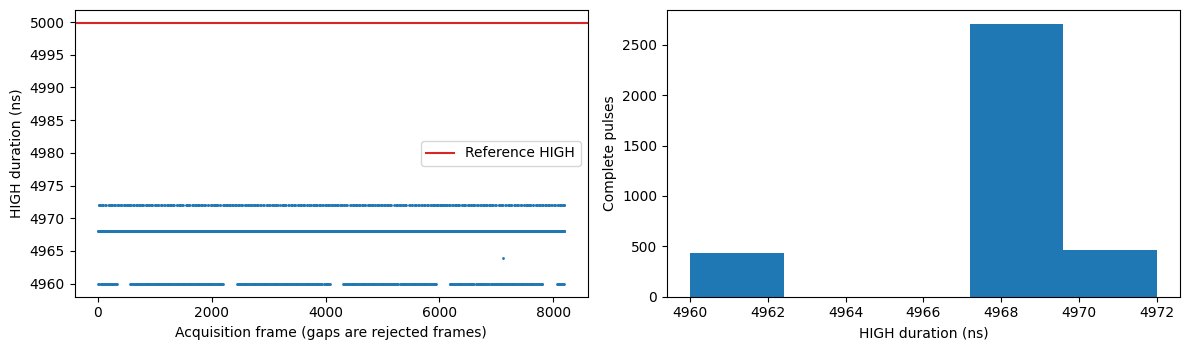

In [42]:
baseline=capture_burst("01_baseline",fine=False)
print("Frame flags:",baseline["flag_counts"])
baseline_summary=show_capture(baseline)
save_json(RUN_DIR/"01_baseline_summary.json",baseline_summary)


### Reference correction using the current coarse measurements

This independent path works even if fine LUT quality gates later fail. Fit one offset to the baseline,
then test it on a fresh burst. It corrects the mean at this setting, not the 4 ns single-shot quantization.
The correction is saved on the PC; it is not written into FPGA registers.
Calibration is blocked for too few accepted pulses, a severely low acceptance rate, or a raw mean far from the reference. A numerical offset must not turn a missing-signal/glitch capture into an apparently correct result.


{
  "accepted_pulses": 3610,
  "total_frames": 8192,
  "rejected_frames": 4582,
  "mean_high_ns": 5000.883672478058,
  "std_high_ns": 1.4440863858508126,
  "mean_error_ns": 1.0336679781930798,
  "reference_high_ns": 4999.850004499865,
  "min_high_ns": 4992.308603225979,
  "max_high_ns": 5004.308603225979,
  "fine_pulses": 0,
  "correction_ns": 32.30860322597891
}


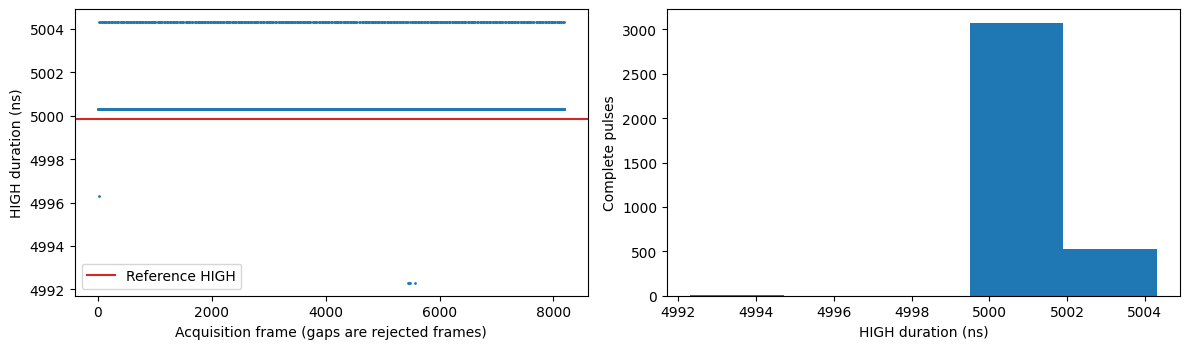

In [43]:
guard_reference_capture(baseline,baseline_summary)
coarse_reference=dict(plan=dict(plan),input="SINGLE",model="one-point host offset on coarse widths",
                      offset_ns=plan["reference_high_ns"]-baseline_summary["mean_high_ns"])
coarse_validation=capture_burst("01a_coarse_reference_validation",fine=False)
guard_reference_capture(coarse_validation,summarize(coarse_validation))
coarse_validation_summary=show_capture(coarse_validation,coarse_reference["offset_ns"])
save_json(RUN_DIR/"01a_coarse_reference.json",dict(calibration=coarse_reference,validation=coarse_validation_summary))

## 4. Collect fine calibration data

Keep the manual generator independent of the FPGA clock; disable any synchronization/locking to it.
The default slightly detuned frequency is intentional. This step collects **raw** rise/fall codes with fine
correction OFF. Incomplete window frames are excluded, but all raw records are saved.
Do not change generator settings during a run. If histogram coverage is poor, change the actual frequency,
update section 1, and restart the run. A phase sweep or longer collection may be needed.

In [44]:
if not isinstance(CAL_BATCHES,int) or CAL_BATCHES<2:
    raise ValueError("Use at least two calibration batches")
calibration_captures=[]
for batch in range(CAL_BATCHES):
    captured=capture_burst(f"02_calibration_{batch:03d}",fine=False)
    calibration_captures.append(captured)
    print(f"Batch {batch+1}/{CAL_BATCHES}: {len(complete_rows(captured))} complete pulses / {len(captured['records'])} windows")

Batch 1/12: 3604 complete pulses / 8192 windows
Batch 2/12: 3602 complete pulses / 8192 windows
Batch 3/12: 3601 complete pulses / 8192 windows
Batch 4/12: 3611 complete pulses / 8192 windows
Batch 5/12: 3613 complete pulses / 8192 windows
Batch 6/12: 3612 complete pulses / 8192 windows
Batch 7/12: 3607 complete pulses / 8192 windows
Batch 8/12: 3607 complete pulses / 8192 windows
Batch 9/12: 3613 complete pulses / 8192 windows
Batch 10/12: 3606 complete pulses / 8192 windows
Batch 11/12: 3605 complete pulses / 8192 windows
Batch 12/12: 3604 complete pulses / 8192 windows


In [45]:
def zero_runs(histogram):
    populated=np.flatnonzero(histogram)
    if len(populated)<2:return []
    runs=[];start=None
    for index in range(int(populated[0]),int(populated[-1])+1):
        if histogram[index]==0 and start is None:start=index
        if histogram[index]!=0 and start is not None:
            runs.append((start,index-1));start=None
    return runs

def build_candidate(captures,min_samples,min_bins,known_dead_zones=()):
    if len(captures)<2 or any(not c["acquisition_ok"] or c["cleanup_errors"] for c in captures):
        raise ValueError("Use at least two successful, clean calibration captures")
    taps=captures[0]["taps"];tick=captures[0]["tick_ps"]
    reference_plan=captures[0]["plan"]
    if any(c["taps"]!=taps or c["tick_ps"]!=tick or c["plan"]!=reference_plan for c in captures):
        raise ValueError("Calibration captures must use identical input/window settings and image dimensions")
    tables={};quality={};histograms={}
    for edge,column,shift in (("RISE",3,16),("FALL",4,24)):
        groups=[];complete_count=0
        for capture in captures:
            rows=complete_rows(capture);complete_count+=len(rows)
            raw=rows[:,column].astype(np.int64)
            good=((rows[:,1]>>shift)&1)!=0
            if np.any(raw[good]>=taps):raise ValueError("Fine raw index exceeds tap count")
            groups.append(raw[good])
        raw=np.concatenate(groups);hist=np.bincount(raw,minlength=taps)
        histograms[edge]=hist
        errors=[]
        if len(raw)<min_samples:errors.append(f"only {len(raw)} valid edge samples; need {min_samples}")
        useful=int(np.count_nonzero(hist))
        if useful<min_bins:errors.append(f"only {useful} populated bins; need {min_bins}; detune/sweep phase")
        retained=len(raw)/max(1,complete_count)
        if retained<0.99:errors.append(f"only {retained:.1%} of complete-pulse {edge} codes encoded validly; phase-selection bias")
        if hist.max(initial=0)>0.15*max(1,len(raw)):errors.append("one bin contains >15% of samples; phase coverage is suspect")
        dead=zero_runs(hist)
        unexpected=[(a,b) for a,b in dead if b-a+1>2 and not any(x<=a and b<=y for x,y in known_dead_zones)]
        if unexpected:errors.append(f"uncharacterized internal missing-code ranges: {unexpected}")
        midpoint=len(groups)//2
        halves=[np.concatenate(groups[:midpoint]),np.concatenate(groups[midpoint:])]
        cdfs=[np.cumsum(np.bincount(part,minlength=taps))/max(1,len(part)) for part in halves]
        distance=float(np.max(np.abs(cdfs[0]-cdfs[1])))
        limit=max(0.03,3*math.sqrt(1/max(1,len(halves[0]))+1/max(1,len(halves[1]))))
        if distance>limit:errors.append(f"first/second-half CDF drift {distance:.3f} exceeds {limit:.3f}")
        # Histogram bin centres in propagation time, normalized to the width
        # sampler's 4000 ps tick, not the legacy TDC's 8000 ps LUT.
        centres=tick*(np.cumsum(hist)-hist/2)/max(1,len(raw))
        tables[edge]=np.rint(centres).astype(int).tolist()
        quality[edge]=dict(samples=len(raw),populated_bins=useful,valid_edge_fraction=retained,
                           missing_code_runs=dead,cdf_drift=distance,errors=errors)
    return dict(taps=taps,tick_ps=tick,plan=dict(reference_plan),input="SINGLE",tables=tables,
                histograms={key:value.tolist() for key,value in histograms.items()},quality=quality,
                ready=all(not q["errors"] for q in quality.values()),
                assumption="Uniform input edge phase over 4 ns; window rejection may bias selection. Candidate, not certified calibration.")

def plot_candidate(candidate):
    fig,axes=plt.subplots(2,2,figsize=(12,6))
    for i,edge in enumerate(("RISE","FALL")):
        axes[i,0].bar(np.arange(candidate["taps"]),candidate["histograms"][edge],width=1)
        axes[i,0].set(title=f"{edge} raw code density",xlabel="Raw tap index",ylabel="Accepted edges")
        axes[i,1].plot(candidate["tables"][edge])
        axes[i,1].set(title=f"{edge} candidate LUT",xlabel="Raw tap index",ylabel="Propagation time (ps)")
    fig.tight_layout();plt.show()

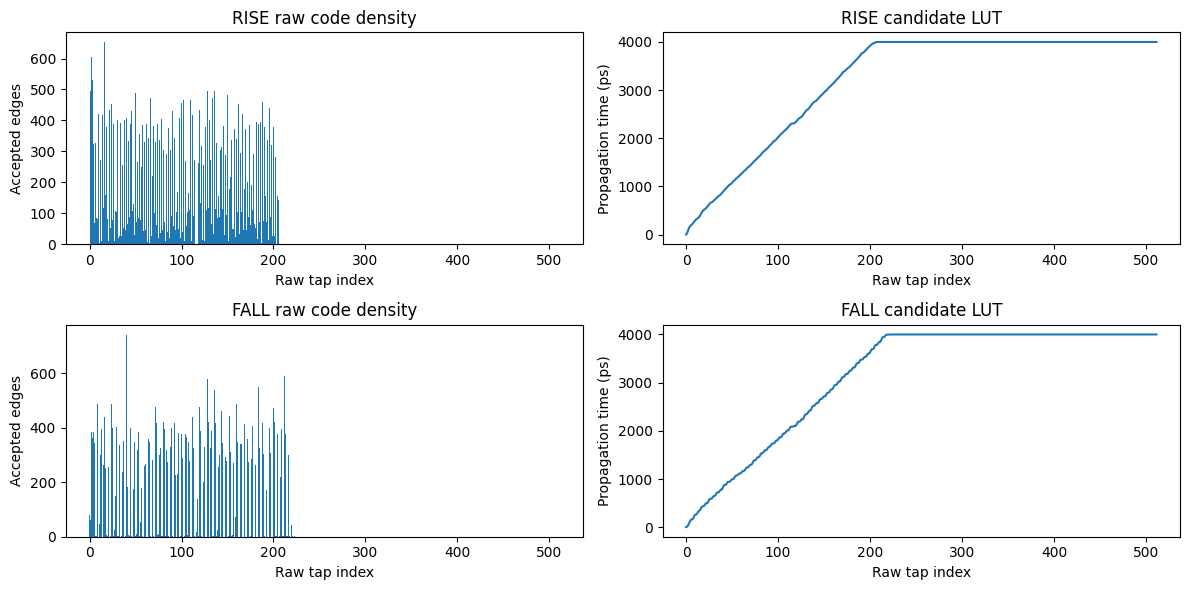

{
  "RISE": {
    "samples": 43138,
    "populated_bins": 204,
    "valid_edge_fraction": 0.9966039043548574,
    "missing_code_runs": [
      [
        115,
        117
      ]
    ],
    "cdf_drift": 0.002404522092861683,
    "errors": [
      "uncharacterized internal missing-code ranges: [(115, 117)]"
    ]
  },
  "FALL": {
    "samples": 39282,
    "populated_bins": 171,
    "valid_edge_fraction": 0.9075199260713873,
    "missing_code_runs": [
      [
        10,
        10
      ],
      [
        14,
        14
      ],
      [
        22,
        22
      ],
      [
        34,
        34
      ],
      [
        38,
        38
      ],
      [
        47,
        47
      ],
      [
        59,
        59
      ],
      [
        62,
        63
      ],
      [
        67,
        67
      ],
      [
        71,
        71
      ],
      [
        87,
        87
      ],
      [
        91,
        91
      ],
      [
        94,
        95
      ],
      [
        98,
       

In [46]:
candidate=build_candidate(calibration_captures,MIN_EDGE_SAMPLES,MIN_POPULATED_BINS,KNOWN_DEAD_ZONES)
save_json(RUN_DIR/"03_candidate_luts.json",candidate)
plot_candidate(candidate)
print(json.dumps(candidate["quality"],indent=2))
print("Candidate passes automatic gates:",candidate["ready"])
if not candidate["ready"]:
    print("Tables will not upload. Increase data or improve phase coverage; characterize missing-code regions rather than guessing them.")

## 5. Upload both candidate LUTs, then measure a fresh burst

Run this after inspecting the histograms and confirming the source is not synchronized to the FPGA.
The upload is blocked if automatic gates fail. All RISE and FALL entries are read back and compared.
These existing commands update RAM calibration tables; they require **no rebuild**. This replaces any
current width calibration, so the previous tables/state are backed up to JSON and restoration is attempted
if upload fails. If you rebuild or change the placed FPGA image/input, recollect calibration.

In [ ]:
def read_table(client,edge,taps):
    values=[]
    for start in range(0,taps,64):
        size=min(64,taps-start)
        part=[int(x) for x in client.ask(f"TDC:WIDTH:CALIBRATION:LUT:READ? {edge},{start},{size}").split(",")]
        if len(part)!=size or any(not 0<=x<=65535 for x in part):raise RuntimeError("Malformed LUT readback")
        values.extend(part)
    return values

def write_table(client,edge,values):
    for start in range(0,len(values),64):
        text=",".join(str(int(x)) for x in values[start:start+64])
        client.write(f"TDC:WIDTH:CALIBRATION:LUT:WRITE {edge},{start},{text}")

def upload_candidate(candidate,client_factory=SCPI):
    if not candidate["ready"] or candidate["plan"]!=plan:
        raise ValueError("Candidate failed gates or generator/window settings changed; recollect")
    if any(len(values)!=candidate["taps"] or any(not 0<=x<=65535 for x in values)
           for values in candidate["tables"].values()):raise ValueError("Invalid LUT dimensions/range")
    client=client_factory(RP_IP,SCPI_PORT);backup=None;changed=False
    try:
        client.write("PULSE:OUTPUT OFF");client.write("TDC:WIDTH:ABORT");wait_idle(client,5)
        if client.ask("TDC:INPUT?").upper()!="SINGLE" or int(client.ask("TDC:TAPS?"))!=candidate["taps"]:
            raise RuntimeError("Input or image dimensions changed since collection")
        backup=dict(enabled=client.ask("TDC:WIDTH:CALIBRATION:ACTIVATE?") in ("1","ON"),
                    tables={edge:read_table(client,edge,candidate["taps"]) for edge in ("RISE","FALL")})
        save_json(RUN_DIR/"04_previous_luts.json",backup)
        changed=True;client.write("TDC:WIDTH:CALIBRATION:ACTIVATE OFF")
        for edge in ("RISE","FALL"):
            write_table(client,edge,candidate["tables"][edge])
            if read_table(client,edge,candidate["taps"])!=candidate["tables"][edge]:
                raise RuntimeError(edge+" LUT readback differs from upload")
        client.write("TDC:WIDTH:CALIBRATION:ACTIVATE ON")
        if client.ask("TDC:WIDTH:CALIBRATION:ACTIVATE?") not in ("1","ON"):
            raise RuntimeError("Calibration activation not confirmed")
        print("Both width LUTs uploaded, read back and activated.")
    except BaseException as exc:
        if changed and backup is not None:
            try:
                client.write("TDC:WIDTH:CALIBRATION:ACTIVATE OFF")
                for edge in ("RISE","FALL"):write_table(client,edge,backup["tables"][edge])
                client.write("TDC:WIDTH:CALIBRATION:ACTIVATE "+("ON" if backup["enabled"] else "OFF"))
            except Exception as restore_error:exc.add_note("LUT restoration could not be confirmed: "+str(restore_error))
        raise
    finally:client.close()

In [ ]:
upload_candidate(candidate)
fine_fit_capture=capture_burst("05_fine_reference_fit",fine=True)
fine_summary=show_capture(fine_fit_capture)
if fine_summary["fine_pulses"]<0.95*fine_summary["accepted_pulses"]:
    raise RuntimeError("Too many coarse fallback pulses; inspect fine-code flags before accepting calibration")
save_json(RUN_DIR/"05_fine_summary.json",fine_summary)

## 6. Reference duration correction and independent validation

One known width identifies an **offset only**, not timebase scale or nonlinearity. The host correction is
`reference HIGH − mean fine HIGH` at this exact frequency/duty/voltage/input point. It is saved locally,
not added to FPGA registers. Validation uses a fresh burst rather than the samples used to fit the offset.
Test other widths separately before applying it more broadly. Generator settings inherit the generator's
uncertainty; use `SCOPE_HIGH_NS` for an independently measured reference when available.

In [ ]:
guard_reference_capture(fine_fit_capture,fine_summary)
reference_calibration=dict(plan=dict(plan),input="SINGLE",source="05_fine_reference_fit",
                           offset_ns=plan["reference_high_ns"]-fine_summary["mean_high_ns"],
                           training_pulses=fine_summary["accepted_pulses"],
                           model="one-point host offset; no scale/nonlinearity calibration")
save_json(RUN_DIR/"06_reference_correction.json",reference_calibration)
validation=capture_burst("07_independent_validation",fine=True)
validation_raw=summarize(validation)
guard_reference_capture(validation,validation_raw)
if validation_raw["fine_pulses"]<0.95*validation_raw["accepted_pulses"]:
    raise RuntimeError("Fresh validation has too many coarse fallbacks; do not accept fine calibration")
validation_corrected=show_capture(validation,reference_calibration["offset_ns"])
save_json(RUN_DIR/"07_validation_summary.json",dict(raw=validation_raw,corrected=validation_corrected))
print(f"Baseline mean error: {baseline_summary['mean_error_ns']:+.3f} ns")
print(f"Fresh fine mean error before host correction: {validation_raw['mean_error_ns']:+.3f} ns")
print(f"Fresh fine mean error after host correction: {validation_corrected['mean_error_ns']:+.3f} ns")
print("Saved records, flags, settings, histograms, LUTs, backup and summaries in",RUN_DIR)

## Stop / recover

After interrupting a running capture, run this cell when the kernel is available. Each burst already
attempts OFF/ABORT in cleanup. A disconnected network can prevent confirmation. To stop the **manual
waveform**, turn off its output at the generator. Fine LUTs remain in FPGA RAM until edited/reset/reloaded.

In [ ]:
stop_fpga()